# 1. Exploración temporal: leer la serie antes de modelarla

Cada valor de la serie es el número de órdenes compradas en un día. Este notebook estudia el nivel, la tendencia, el patrón semanal, la estacionariedad, la dependencia del pasado y los episodios atípicos. Cierra con las decisiones que quedan fijadas para [B_series_02_modelado](B_series_02_modelado.ipynb).

**Recorrido**

0. Qué datos mira cada análisis y decisiones de diseño del análisis
1. Protocolo *walk-forward*
2. Análisis de la serie: tendencia, estacionalidad semanal, escala logarítmica, STL, ADF/KPSS, ACF/PACF y AIC orientativo
3. Eventos atípicos: identificación, magnitud y tratamiento (modelar, marcar o excluir)
4. Decisiones para el modelado

## 0. Qué datos mira cada análisis

Un error frecuente al explorar una serie es calcular la STL, las pruebas de estacionariedad, la ACF/PACF o el efecto de los eventos con la **serie completa, incluida la prueba**. Esos análisis deciden la forma del modelo (transformación, diferenciación, estacionalidad, eventos), así que la prueba terminaría influyendo en el mismo modelo que luego se evalúa con ella.

La regla de este notebook es una sola: **una decisión de especificación solo puede usar información disponible antes de la emisión que la va a aplicar.** De ahí salen tres ventanas:

| Ventana | Fechas | Para qué se usa | Por qué |
|---|---|---|---|
| **Especificación** | 2017-02-01 a 2017-07-23 (primer origen de selección) | Perfil semanal, escala logarítmica, STL, ADF/KPSS, ACF/PACF y AIC orientativo | El modelo queda fijado antes de la primera emisión de selección: ninguna fecha que se va a evaluar influye en su forma. |
| **Contexto previo a prueba** | 2017-02-01 a 2018-06-24 (primer origen de prueba) | Describir la tendencia, identificar y medir eventos, comprobar que las conclusiones se mantienen | Todo esto ya se conocía al emitir el primer pronóstico de prueba. Black Friday 2017 (selección) y la huelga de 2018 (calibración) solo existen en esta ventana. Sus resultados **describen y controlan**; no reabren la especificación. |
| **Prueba** | 2018-06-25 a 2018-08-19 | Nada en este notebook | La serie se reconstruye en SQL solo hasta 2018-06-24: los valores de prueba ni siquiera se cargan en memoria. |

### Decisiones de diseño del análisis

| Procedimiento | Cómo se hace aquí | Por qué |
|---|---|---|
| Escala | Pruebas, descomposiciones y ACF sobre `log(1 + y)` | Es la escala en la que SARIMAX se ajusta en 02 (§2.3). |
| STL, ADF/KPSS, ACF/PACF | Ventana de especificación; ADF/KPSS, STL y perfil semanal se repiten con el historial previo a prueba solo como control | Ni la prueba ni las fechas que se van a evaluar moldean la especificación. |
| AIC orientativo de SARIMAX | Datos hasta 2017-07-23 | El orden se fija con la información disponible en la primera emisión de selección. |
| Perfil semanal | Razón día / media centrada de 7 días, en SQL, sin días con evento ni días cuya semana centrada contiene uno | Un pico como Black Friday inflaría la media centrada de sus vecinos. |
| Magnitud de los eventos | Observado frente a la mediana del mismo día en las 4 semanas previas, en SQL | Solo usa pasado y tolera que una semana de referencia también sea atípica. |
| Detección de atípicos | Además de la lista de eventos, residuo STL robusto estandarizado con la MAD | Encuentra días raros que no están en ninguna lista, como el 21-jun-2017. |
| Huelga de camioneros | Se marca y se conserva: sin indicador y dentro de las métricas | Excluirla haría las métricas y los intervalos más optimistas que la operación real (§3.3). |
| Mundial 2018 | Solo los dos partidos de Brasil anteriores a la prueba | Los demás caen en prueba. |
| Carnaval | Se mide en 2017 y 2018 y se incorpora al calendario como indicador | Su fecha se conoce de antemano y su efecto de 2017 está dentro de la ventana de especificación (§3.3). |

In [1]:
# La ruta funciona tanto al abrir notebooks/ como desde la raíz del proyecto.
from pathlib import Path
import sys, warnings
ROOT=Path.cwd() if (Path.cwd()/'sql').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from src.configuracion import INICIO, CORTE, FIN, HORIZONTE, SELECCION, CALIBRACION, PRUEBA, EPISODIOS, particiones
from src.datos import conectar, consultar, preparar, exportar
pd.set_option('display.max_columns',20); pd.set_option('display.max_rows',60); pd.set_option('display.width',160)
(ROOT/'resultados').mkdir(exist_ok=True)
(ROOT/'documentacion/figuras').mkdir(parents=True,exist_ok=True)

# Estilo común (src/estilo.py): Source Sans 3, grilla tenue y un color fijo por etapa.
from src.estilo import aplicar_estilo, TINTA, TENUE, ETAPA as COLOR, FONDO, MESES, DIAS, fechas_es, figura, mostrar
aplicar_estilo()

In [2]:
con=conectar()  # read_only=True: el análisis no escribe en la base original.
DIAGNOSTICO,PREPRUEBA=SELECCION[0],PRUEBA[0]
D,P=str(DIAGNOSTICO.date()),str(PREPRUEBA.date())
# 1) El calendario se conoce de antemano: se construye completo, con fechas posteriores al corte.
_,calendario,_=preparar(con)
# 2) La serie se reconstruye en SQL solo hasta el primer origen de prueba:
#    las órdenes de prueba no quedan en memoria y ningún cálculo puede usarlas.
serie,_,_=preparar(con,fin=P)
con.register('calendario',calendario)
con.register('episodios',EPISODIOS)
etiquetas=consultar(con,'etiquetas_eventos.sql'); con.register('etiquetas',etiquetas)
y=serie.set_index('fecha').y.asfreq('D')
y_diag=y.loc[:DIAGNOSTICO]
partes=particiones()
assert y.index.max()==PREPRUEBA<partes[partes.etapa.eq('prueba')].desde.min()
ventanas=pd.DataFrame([
    ['Especificación',INICIO,D,len(y_diag),'Perfil semanal, escala log, STL, ADF/KPSS, ACF/PACF, AIC'],
    ['Contexto previo a prueba',INICIO,P,len(y),'Tendencia, eventos y controles de estabilidad'],
    ['Prueba',str((PREPRUEBA+pd.Timedelta(days=1)).date()),FIN,(pd.Timestamp(FIN)-PREPRUEBA).days,'Ninguno: no se carga']],
    columns=['ventana','desde','hasta','dias','uso'])
mostrar(ventanas,'Ventanas de datos de este notebook','Cada análisis declara su ventana; ninguna llega a las fechas de prueba.')


■ Ventanas de datos de este notebook
  Cada análisis declara su ventana; ninguna llega a las fechas de prueba.


,ventana,desde,hasta,dias,uso
0,Especificación,2017-02-01,2017-07-23,173,"Perfil semanal, escala log, STL, ADF/KPSS, ACF..."
1,Contexto previo a prueba,2017-02-01,2018-06-24,509,"Tendencia, eventos y controles de estabilidad"
2,Prueba,2018-06-25,2018-08-19,56,Ninguno: no se carga


## 1. Protocolo *walk-forward*: separar el tiempo antes de estudiar el modelo

Una **fecha de origen** es el último día observado; al cierre de ese día se emite un pronóstico para los 28 días siguientes (horizonte `h = 1…28`). Los orígenes son **domingos**, así que cada emisión cubre cuatro semanas completas de lunes a domingo.

Hay tres etapas con funciones distintas: **selección** elige el modelo, **calibración** estima los márgenes de error y **prueba** describe el desempeño final una sola vez. En cada emisión el modelo se reajusta con toda la historia hasta su origen (ventana **expansiva**), como ocurriría en operación. Las fechas objetivo no se cruzan entre etapas. Dentro de una etapa sí se solapan: una misma fecha recibe pronósticos emitidos con distintas anticipaciones, así que las predicciones no son observaciones independientes.


■ Etapas del protocolo walk-forward
  Cada emisión parte del cierre de un domingo y pronostica los 28 días siguientes.


,emisiones,primer_origen,ultimo_origen,objetivos_desde,objetivos_hasta
etapa,,,,,
seleccion,30,2017-07-23,2018-02-11,2017-07-24,2018-03-11
calibracion,12,2018-03-11,2018-05-27,2018-03-12,2018-06-24
prueba,5,2018-06-24,2018-07-22,2018-06-25,2018-08-19


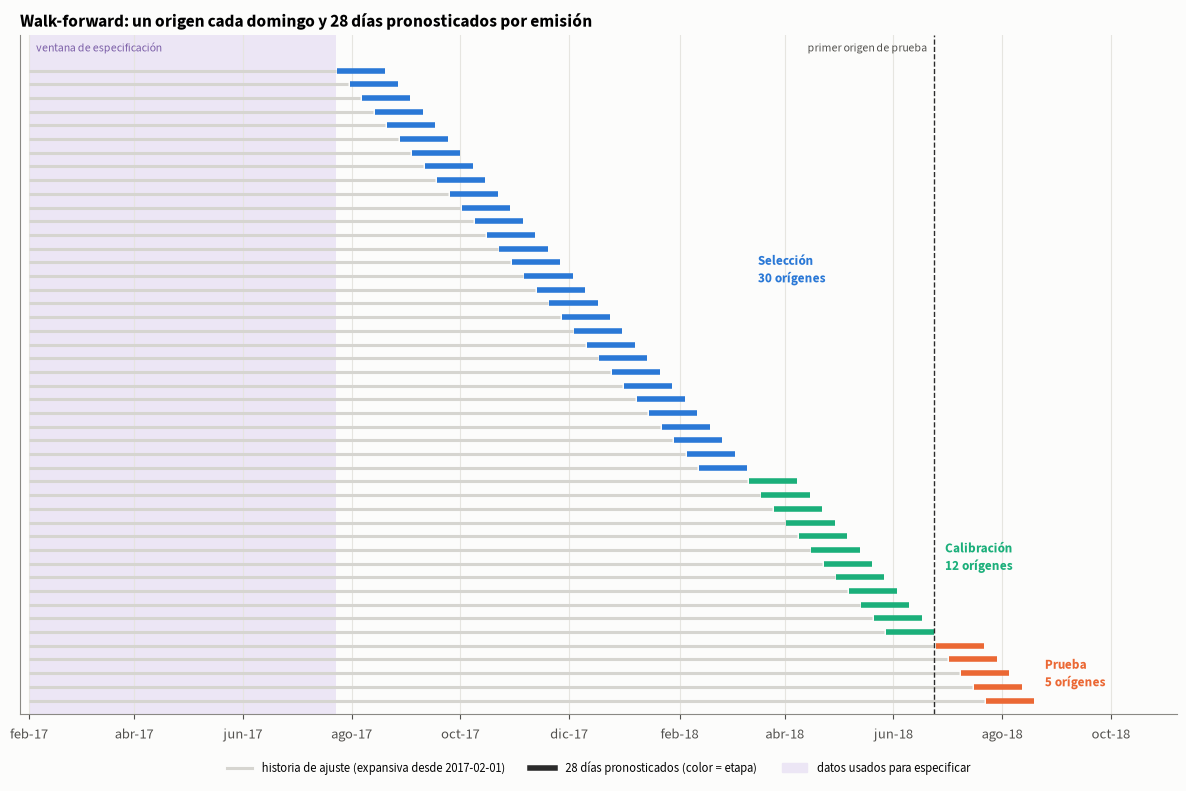

In [3]:
# Las fronteras son parte del diseño, no el resultado de probar modelos.
exportar(partes,'particiones')
resumen=partes.groupby('etapa',sort=False).agg(emisiones=('origen','size'),
    primer_origen=('origen','min'),ultimo_origen=('origen','max'),
    objetivos_desde=('desde','min'),objetivos_hasta=('hasta','max'))
mostrar(resumen,'Etapas del protocolo walk-forward','Cada emisión parte del cierre de un domingo y pronostica los 28 días siguientes.')
assert partes[partes.etapa.eq('seleccion')].hasta.max()<partes[partes.etapa.eq('calibracion')].desde.min()
assert partes[partes.etapa.eq('calibracion')].hasta.max()<partes[partes.etapa.eq('prueba')].desde.min()

fig,ax=plt.subplots(figsize=(12,8))
inicio=pd.Timestamp(INICIO); n=len(partes)
ax.axvspan(inicio,DIAGNOSTICO,color=FONDO['diagnostico'],lw=0,zorder=0)
for i,f in enumerate(partes.itertuples()):
    fila=n-i  # la primera emisión arriba
    ax.plot([inicio,f.origen],[fila,fila],color='#d6d5d0',lw=2.2,solid_capstyle='butt')
    ax.plot([f.desde,f.hasta],[fila,fila],color=COLOR[f.etapa],lw=4,solid_capstyle='butt')
for etapa,nombre in [('seleccion','Selección'),('calibracion','Calibración'),('prueba','Prueba')]:
    g=partes[partes.etapa.eq(etapa)]
    ax.text(g.hasta.max()+pd.Timedelta(days=6),(n-g.index.to_numpy()).mean(),f'{nombre}\n{len(g)} orígenes',
            color=COLOR[etapa],fontsize=9.5,fontweight='bold',va='center')
ax.axvline(PREPRUEBA,color=TINTA,lw=1,ls='--')
ax.text(PREPRUEBA-pd.Timedelta(days=4),n+1.4,'primer origen de prueba',ha='right',fontsize=8.5,color='#52514e')
ax.text(inicio+pd.Timedelta(days=4),n+1.4,'ventana de especificación',fontsize=8.5,color=COLOR['diagnostico'])
ax.set_ylim(0,n+2.6); ax.set_yticks([]); ax.grid(axis='y',visible=False)
ax.set_xlim(inicio-pd.Timedelta(days=5),pd.Timestamp(FIN)+pd.Timedelta(days=80))
fechas_es(ax,'mes',2)
ax.legend(handles=[Line2D([],[],color='#d6d5d0',lw=2.2,label='historia de ajuste (expansiva desde 2017-02-01)'),
                   Line2D([],[],color=TINTA,lw=4,label='28 días pronosticados (color = etapa)'),
                   Patch(color=FONDO['diagnostico'],label='datos usados para especificar')],
          loc='upper center',bbox_to_anchor=(.5,-.05),ncol=3,fontsize=9)
ax.set_title('Walk-forward: un origen cada domingo y 28 días pronosticados por emisión')
figura('protocolo_temporal')

**Lectura del gráfico.** Cada fila es una emisión, de la primera (arriba) a la última (abajo). La línea gris es la historia disponible para ajustar: siempre empieza el 2017-02-01 y crece una semana por fila. La barra de color son los 28 días que pronostica esa emisión.

- Entre el último origen de una etapa y el primero de la siguiente hay cuatro semanas (11-feb → 11-mar y 27-may → 24-jun). Ese salto garantiza que ningún día objetivo pertenezca a dos etapas.
- La franja violeta es la ventana de especificación y termina justo en el primer origen de selección. Todo lo que este notebook decide sobre la forma del modelo se apoya solo en esa franja.
- La línea punteada marca el primer origen de prueba. A su derecha no se examina nada aquí.

**Consecuencia para 02.** La primera emisión de selección se ajusta con solo 173 días, y los orígenes de selección anteriores a noviembre de 2017 nunca han visto un Black Friday. El indicador existe en el calendario, pero su coeficiente no se puede estimar hasta que ocurre el primero. Empezar la validación en enero de 2018 lo evitaría, pero con muchas menos emisiones. Aquí se acepta ese costo a cambio de que la selección recorra casi un año de condiciones distintas (crecimiento, Black Friday, fin de año, Carnaval).

## 2. Análisis de la serie

### 2.1 Tendencia y nivel

El **nivel** es la magnitud habitual de pedidos y la **tendencia**, su evolución lenta. La media móvil de 28 días usa el día actual y los 27 anteriores (ventana causal, calculada en SQL). La figura cubre todo el historial previo a prueba; las franjas de color indican a qué etapa pertenece cada tramo de fechas y la zona rayada, la prueba, que no se dibuja.

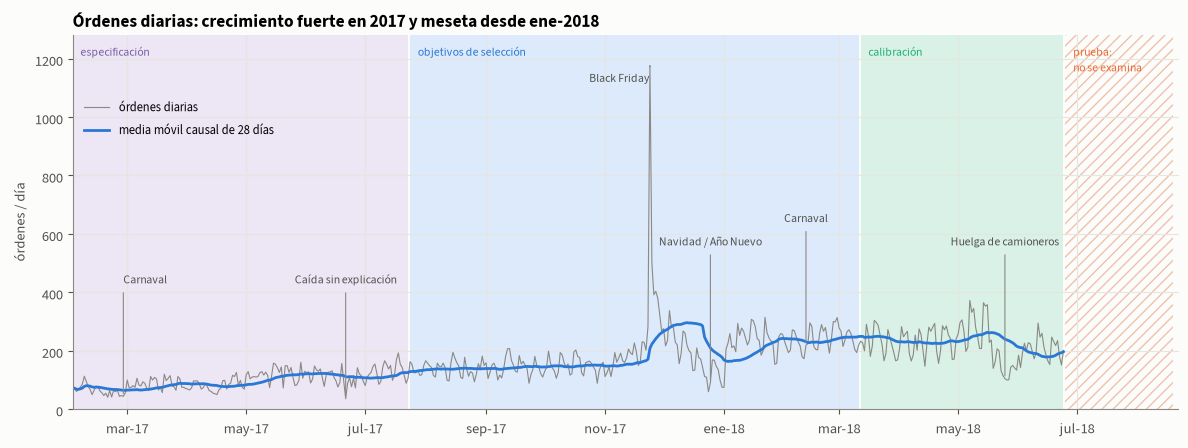


■ Promedio diario de órdenes por mes (historial previo a prueba)
  jun-18 llega solo hasta el día 24, el primer origen de prueba.


,mes,dias,ordenes,media_diaria
0,feb-17,28,1780.0,63.6
1,mar-17,31,2682.0,86.5
2,abr-17,30,2404.0,80.1
3,may-17,31,3700.0,119.4
4,jun-17,30,3245.0,108.2
5,jul-17,31,4026.0,129.9
6,ago-17,31,4331.0,139.7
7,sep-17,30,4285.0,142.8
8,oct-17,31,4631.0,149.4
9,nov-17,30,7544.0,251.5


feb-17: 64 → oct-17: 149 órdenes diarias (×2.3). Ene–may 2018: entre 222 y 240 (8% de rango).


In [4]:
moviles=consultar(con,'diagnostico.sql',[P]); exportar(moviles,'medias_moviles_preprueba')
mensual=consultar(con,'promedio_mensual.sql',[P]); exportar(mensual,'promedio_mensual')
objetivos=partes.groupby('etapa').agg(desde=('desde','min'),hasta=('hasta','max'))

fig,ax=plt.subplots(figsize=(12,4.6))
ax.axvspan(pd.Timestamp(INICIO),DIAGNOSTICO,color=FONDO['diagnostico'],lw=0)
for etapa in ['seleccion','calibracion']:
    ax.axvspan(objetivos.loc[etapa,'desde'],objetivos.loc[etapa,'hasta'],color=FONDO[etapa],lw=0)
ax.axvspan(objetivos.loc['prueba','desde'],objetivos.loc['prueba','hasta'],facecolor='none',
           edgecolor='#f0c2ab',hatch='///',lw=0)
ax.plot(moviles.fecha,moviles.y,color=TENUE,lw=.8,label='órdenes diarias')
ax.plot(moviles.fecha,moviles.media_28,color=COLOR['seleccion'],lw=2,label='media móvil causal de 28 días')
# (texto, fecha, altura del texto, alineación)
EVENTOS_GRAFICO=[('Carnaval','2017-02-27',430,'left'),('Caída sin explicación','2017-06-21',430,'center'),
                 ('Black Friday','2017-11-24',1120,'right'),('Navidad / Año Nuevo','2017-12-25',560,'center'),
                 ('Carnaval','2018-02-12',640,'center'),('Huelga de camioneros','2018-05-25',560,'center')]
for nombre,fecha,altura,alineacion in EVENTOS_GRAFICO:
    f=pd.Timestamp(fecha)
    # relpos ancla la línea al borde del texto que queda sobre el punto.
    ax.annotate(nombre,(f,y[f]),xytext=(f,altura),ha=alineacion,fontsize=8.5,color='#52514e',
                arrowprops=dict(arrowstyle='-',color=TENUE,lw=.8,relpos=({'left':0,'center':.5,'right':1}[alineacion],0)))
for texto,x,color in [('especificación',pd.Timestamp(INICIO),COLOR['diagnostico']),
                      ('objetivos de selección',objetivos.loc['seleccion','desde'],COLOR['seleccion']),
                      ('calibración',objetivos.loc['calibracion','desde'],COLOR['calibracion']),
                      ('prueba:\nno se examina',objetivos.loc['prueba','desde'],COLOR['prueba'])]:
    ax.text(x+pd.Timedelta(days=4),1250,texto,fontsize=8.5,color=color,va='top')
ax.set_ylim(0,1280); ax.set_xlim(pd.Timestamp(INICIO),pd.Timestamp(FIN)+pd.Timedelta(days=3))
fechas_es(ax,'mes',2); ax.set_ylabel('órdenes / día')
ax.legend(loc='upper left',bbox_to_anchor=(0,.86),fontsize=9)
ax.set_title('Órdenes diarias: crecimiento fuerte en 2017 y meseta desde ene-2018')
figura('serie_tendencia')

mensual['mes']=pd.to_datetime(mensual.mes)
m=mensual.set_index('mes').media_diaria
feb17,oct17=m[pd.Timestamp('2017-02-01')],m[pd.Timestamp('2017-10-01')]
meseta=m[pd.Timestamp('2018-01-01'):pd.Timestamp('2018-05-01')]
mostrar(mensual.assign(mes=[f'{MESES[d.month-1]}-{d:%y}' for d in mensual.mes]).round(1),
        'Promedio diario de órdenes por mes (historial previo a prueba)','jun-18 llega solo hasta el día 24, el primer origen de prueba.')
print(f'feb-17: {feb17:.0f} → oct-17: {oct17:.0f} órdenes diarias (×{oct17/feb17:.1f}). '
      f'Ene–may 2018: entre {meseta.min():.0f} y {meseta.max():.0f} ({meseta.max()/meseta.min()-1:.0%} de rango).')

**Lectura del gráfico.** La media móvil sube de unas 64 órdenes diarias en febrero de 2017 a unas 149 en octubre (×2.3): un crecimiento fuerte y casi lineal durante 2017. Noviembre se dispara por Black Friday y diciembre cae por fin de año. Desde enero de 2018 la serie queda en una **meseta** de 222 a 240 órdenes diarias, con un descenso en mayo-junio que coincide con la huelga. Las anotaciones señalan los episodios que se analizan en la sección 3.

**Qué implica para el modelado**

- La tendencia **no es estable**: el crecimiento de 2017 no continúa en 2018. Un modelo con tendencia lineal fija o con deriva extrapolaría un crecimiento que ya no ocurre. Por eso, en 02, SARIMAX usa `d = 1` **sin** constante de deriva (`trend='n'`), ETS usa tendencia **amortiguada** y LightGBM tiene variantes con objetivo relativo a la media de 28 días del origen, porque un árbol no extrapola niveles que no vio.
- La ventana de especificación cubre solo la fase de crecimiento. Las conclusiones que podrían depender del régimen (patrón semanal, orden de diferenciación, fuerza de la tendencia) se comprueban más abajo con todo el historial previo a prueba.
- Noviembre y diciembre no representan el nivel típico: sus promedios están dominados por eventos de calendario.

### 2.2 Estacionalidad semanal

Para aislar el patrón semanal del nivel, cada día se divide por la media centrada de 7 días que lo rodea (3 antes, el propio día y 3 después). Una razón de 1.15 significa un día 15 % por encima de su semana. Se descartan los días con evento y también aquellos cuya semana centrada contiene un evento, para que un pico no deforme la razón de sus vecinos. Las cajas comparan la ventana de especificación con todo el historial previo a prueba.

La media centrada usa tres días posteriores: sirve para **describir**, no como variable de un modelo.

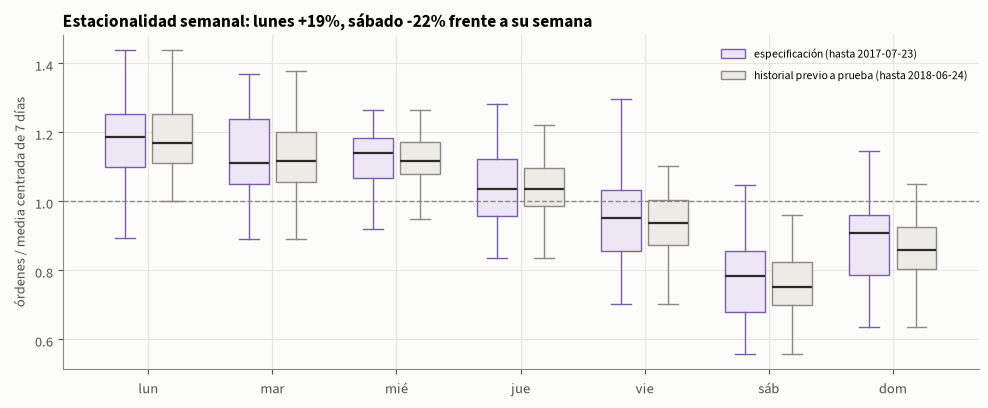


■ Razón día / semana por ventana: mediana, desviación y días usados
  1 = día promedio de su semana. Sin días con evento ni sus vecinos.


mediana            desviacion                  dias          
ventana diagnostico preprueba diagnostico preprueba diagnostico preprueba
lun           1.187     1.168       0.208     0.147        20.0      52.0
mar           1.112     1.116       0.159     0.132        20.0      51.0
mié           1.139     1.116       0.189     0.140        20.0      51.0
jue           1.035     1.035       0.114     0.093        20.0      50.0
vie           0.952     0.938       0.142     0.104        18.0      48.0
sáb           0.782     0.751       0.129     0.099        20.0      52.0
dom           0.907     0.859       0.126     0.102        20.0      52.0


■ Órdenes por día de la semana en la ventana de especificación (escala original)
  Media y mediana de órdenes; aquí sí entran los días con evento.


,dias,media,mediana
dia,,,
lun,24,112.1,116.0
mar,24,109.9,108.0
mié,25,105.4,105.0
jue,25,100.9,103.0
vie,25,91.4,88.0
sáb,25,74.5,75.0
dom,25,85.1,88.0


In [5]:
perfil=pd.concat([consultar(con,'perfil_semanal.sql',[D]).assign(ventana='diagnostico'),
                  consultar(con,'perfil_semanal.sql',[P]).assign(ventana='preprueba')],ignore_index=True)
con.register('perfil',perfil)
resumen_perfil=consultar(con,'resumen_perfil_semanal.sql'); exportar(resumen_perfil,'perfil_semanal')
patron=consultar(con,'patron_semanal.sql',[D]); exportar(patron,'patron_semanal')
mediana=resumen_perfil.pivot(index='dia_semana',columns='ventana',values='mediana')

fig,ax=plt.subplots(figsize=(10,4.2)); manijas=[]
for desplazamiento,ventana,etiqueta,color,relleno in [
        (-.19,'diagnostico',f'especificación (hasta {D})',COLOR['diagnostico'],FONDO['diagnostico']),
        (.19,'preprueba',f'historial previo a prueba (hasta {P})',TENUE,'#ecebe6')]:
    g=perfil[perfil.ventana.eq(ventana)]
    cajas=ax.boxplot([g.razon[g.dia_semana.eq(d)] for d in range(1,8)],positions=np.arange(1,8)+desplazamiento,
                     widths=.32,patch_artist=True,showfliers=False,medianprops=dict(color=TINTA,lw=1.6),
                     whiskerprops=dict(color=color),capprops=dict(color=color))
    for caja in cajas['boxes']: caja.set(facecolor=relleno,edgecolor=color)
    manijas.append(Patch(facecolor=relleno,edgecolor=color,label=etiqueta))
ax.axhline(1,color=TENUE,lw=1,ls='--')
ax.set_xticks(range(1,8),DIAS); ax.set_ylabel('órdenes / media centrada de 7 días')
ax.legend(handles=manijas,loc='upper right',fontsize=8.5)
lun,sab=mediana.loc[1,'diagnostico'],mediana.loc[6,'diagnostico']
ax.set_title(f'Estacionalidad semanal: lunes {lun-1:+.0%}, sábado {sab-1:+.0%} frente a su semana')
figura('perfil_semanal')

tabla=resumen_perfil.pivot(index='dia_semana',columns='ventana',values=['mediana','desviacion','dias']).round(3)
tabla.index=DIAS
mostrar(tabla,'Razón día / semana por ventana: mediana, desviación y días usados',
        '1 = día promedio de su semana. Sin días con evento ni sus vecinos.')
mostrar(patron.assign(dia=DIAS).set_index('dia').drop(columns='dia_semana').round(1),
        'Órdenes por día de la semana en la ventana de especificación (escala original)',
        'Media y mediana de órdenes; aquí sí entran los días con evento.')

**Lectura del gráfico.** El lunes es el día más alto (≈ +19 %) y la demanda baja de forma escalonada hasta el sábado, el más bajo (≈ −22 %); el domingo recupera en parte. Las medianas de las dos ventanas casi coinciden (lunes 1.19 frente a 1.17; sábado 0.78 frente a 0.75) y las cajas del historial más largo son más estrechas. El patrón es **estable** y **multiplicativo**: un porcentaje del nivel, no una cantidad fija de órdenes, aunque el nivel casi se cuadruplicó entre febrero de 2017 y 2018. El domingo es el día que más se mueve entre ventanas (0.91 frente a 0.86).

**Qué implica para el modelado**

- Un patrón semanal estable se representa bien como **estacionalidad determinística**: seis indicadores de día de la semana (domingo como referencia) en SARIMAX y la variable `dia_semana` en LightGBM. No hace falta una diferencia estacional, que trataría el patrón como algo que cambia al azar de una semana a otra (se contrasta en §2.6 y §2.7).
- Como el efecto es proporcional al nivel, conviene modelar en escala logarítmica, donde un efecto multiplicativo se vuelve aditivo (§2.3).
- La referencia `Estacional_7` (repetir la última semana) es una vara exigente: captura este patrón sin estimar nada.

### 2.3 ¿Por qué modelar log(1 + y)?

Si la amplitud de las oscilaciones crece con el nivel, un modelo aditivo en escala original subestima la variación en los meses altos y la sobreestima en los bajos. Para comprobarlo se calcula, por semana completa de lunes a domingo, la media y la desviación estándar diaria, en escala original y tras aplicar `log(1 + y)`. Las semanas con algún día de evento se dibujan huecas y no entran en la correlación `r`.

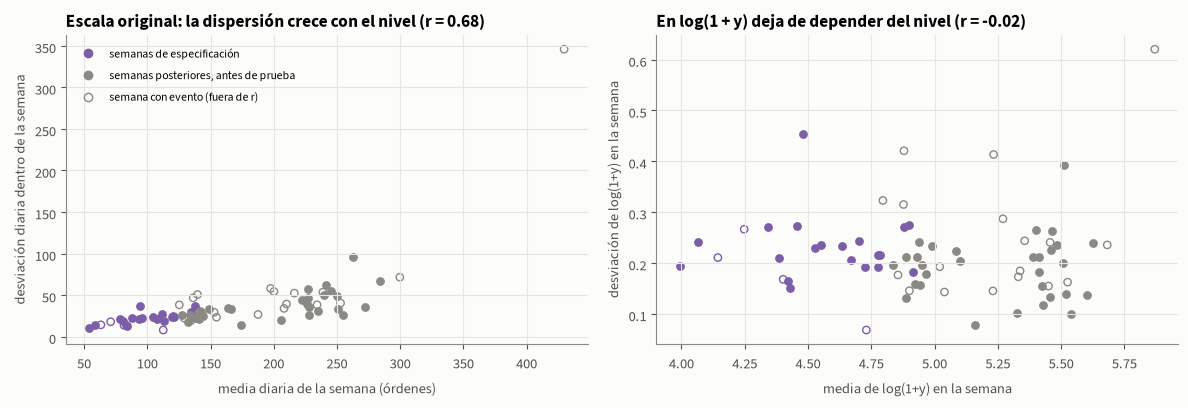


■ Correlación entre nivel y dispersión semanal, por ventana
  Sin semanas con evento. cv_medio = desviación / media en escala original.


,ventana,semanas,corr_original,corr_log,cv_medio
0,diagnostico,20,0.681,-0.016,0.222
1,posterior,30,0.639,0.064,0.184


In [6]:
# Nivel y dispersión por semana completa, en SQL; la correlación también se calcula en SQL.
amplitud=consultar(con,'amplitud_semanal.sql',[D,P]); exportar(amplitud,'amplitud_semanal')
con.register('amplitud',amplitud)
resumen_amplitud=consultar(con,'resumen_amplitud.sql'); exportar(resumen_amplitud,'resumen_amplitud')
r=resumen_amplitud.set_index('ventana')

fig,ejes=plt.subplots(1,2,figsize=(12,4.2))
for eje,(x,dispersion,etiqueta) in zip(ejes,[('media','desviacion','desviación diaria dentro de la semana'),
                                             ('media_log','desviacion_log','desviación de log(1+y) en la semana')]):
    for ventana,color in [('diagnostico',COLOR['diagnostico']),('posterior',TENUE)]:
        g=amplitud[amplitud.ventana.eq(ventana)]; limpia=g.dias_evento.eq(0)
        eje.scatter(g[x][limpia],g[dispersion][limpia],color=color,s=28)
        eje.scatter(g[x][~limpia],g[dispersion][~limpia],facecolor='none',edgecolor=color,s=28)
    eje.set_ylabel(etiqueta)
ejes[0].set_xlabel('media diaria de la semana (órdenes)'); ejes[1].set_xlabel('media de log(1+y) en la semana')
ejes[0].set_title(f'Escala original: la dispersión crece con el nivel (r = {r.loc["diagnostico","corr_original"]:.2f})')
ejes[1].set_title(f'En log(1 + y) deja de depender del nivel (r = {r.loc["diagnostico","corr_log"]:.2f})')
ejes[0].legend(handles=[Line2D([],[],ls='',marker='o',color=COLOR['diagnostico'],label='semanas de especificación'),
                        Line2D([],[],ls='',marker='o',color=TENUE,label='semanas posteriores, antes de prueba'),
                        Line2D([],[],ls='',marker='o',mfc='none',color=TENUE,label='semana con evento (fuera de r)')],
               loc='upper left',fontsize=8.5)
figura('amplitud_nivel')
mostrar(resumen_amplitud.round(3),'Correlación entre nivel y dispersión semanal, por ventana',
        'Sin semanas con evento. cv_medio = desviación / media en escala original.')

**Lectura del gráfico.** En escala original la desviación dentro de la semana crece con el nivel. La correlación es clara en la ventana de especificación, y las semanas posteriores, con más órdenes, prolongan la nube hacia arriba. En `log(1 + y)` la nube queda horizontal y la correlación cae a cerca de cero: la dispersión ya no depende del nivel. El coeficiente de variación ronda 0.2 en las dos ventanas, otra forma de decir que la oscilación es un porcentaje casi fijo del nivel.

**Qué implica para el modelado.** SARIMAX se ajusta sobre `log1p(y)` y se devuelve a órdenes con `expm1`, su inversa exacta; el `+1` evita el logaritmo de cero. Al invertir, el pronóstico puntual se acerca a una mediana, no a una media, en escala original. LightGBM aplica la misma idea en su objetivo relativo `log(1+y) − log(1+media_28)`. Las pruebas de estacionariedad y la ACF se calculan en esta escala para que describan la serie que se modela.

### 2.4 Descomposición STL

STL (*Seasonal-Trend decomposition using LOESS*) separa la serie en **tendencia + estacional + residuo**. Se aplica a `log(1 + y)`, donde la estacionalidad es aditiva (§2.3), con período 7 y versión **robusta**, que reduce el peso de los días extremos al estimar tendencia y estacionalidad. La figura usa solo la ventana de especificación.

El residuo es lo que la descomposición no explica; no es el error de un pronóstico. STL usa vecinos posteriores dentro del tramo, así que sus componentes sirven para describir y nunca como variables de un modelo.

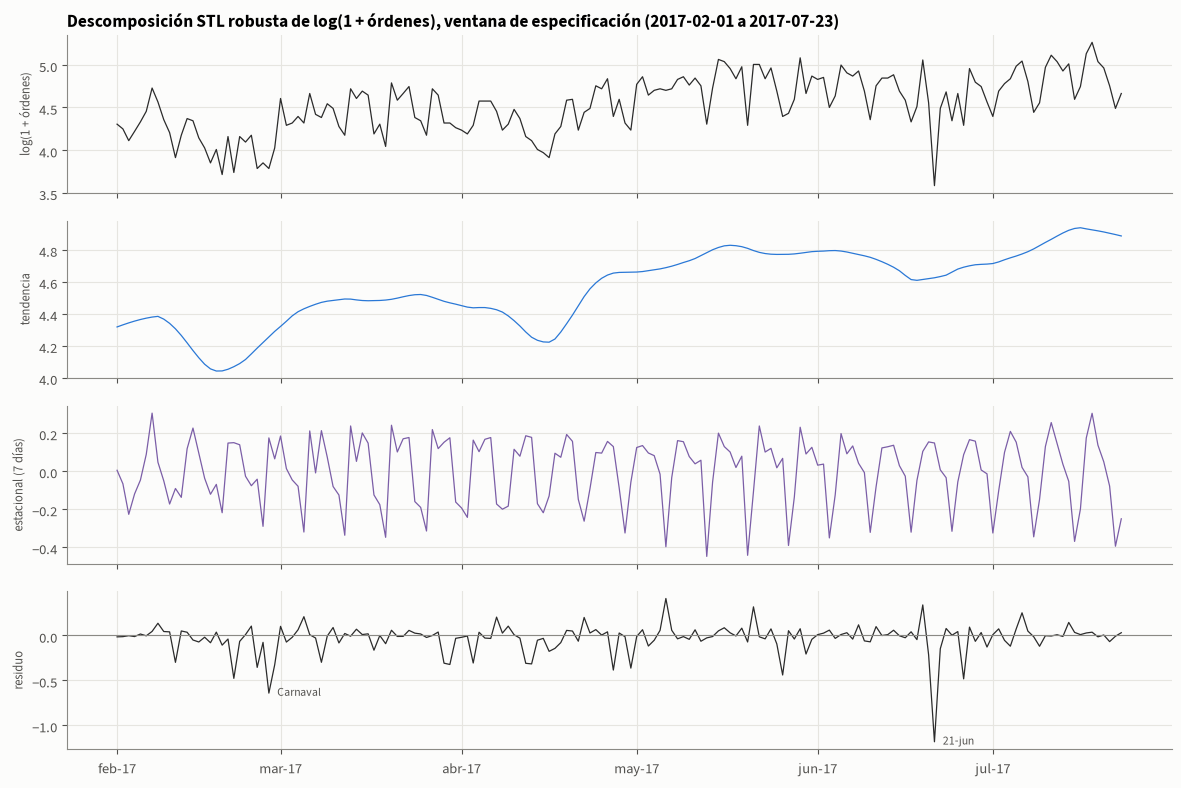


■ Fuerza de la tendencia y de la estacionalidad semanal (0 = nula, 1 = domina)
  Fuerza = 1 − Var(residuo) / Var(componente + residuo).


,ventana,fuerza_tendencia,fuerza_estacional
0,especificación,0.71,0.42
1,previa a prueba,0.87,0.44


Tendencia en log: de 4.32 a 4.88 (×1.8 en órdenes).


In [7]:
# Descomponemos solo la ventana de especificación; STL nunca se usa como predictor.
from statsmodels.tsa.seasonal import STL
log_diag=np.log1p(y_diag)
stl=STL(log_diag,period=7,robust=True).fit()

fig,ejes=plt.subplots(4,1,figsize=(12,8),sharex=True)
for eje,(nombre,comp,color) in zip(ejes,[('log(1 + órdenes)',log_diag,TINTA),('tendencia',stl.trend,COLOR['seleccion']),
                                         ('estacional (7 días)',stl.seasonal,COLOR['diagnostico']),('residuo',stl.resid,TINTA)]):
    eje.plot(comp.index,comp.values,color=color,lw=.9); eje.set_ylabel(nombre,fontsize=9)
ejes[3].axhline(0,color=TENUE,lw=.8)
for nombre,fecha in [('Carnaval','2017-02-27'),('21-jun','2017-06-21')]:
    f=pd.Timestamp(fecha)
    ejes[3].annotate(nombre,(f,stl.resid[f]),xytext=(6,-2),textcoords='offset points',fontsize=8.5,color='#52514e')
ejes[0].set_title(f'Descomposición STL robusta de log(1 + órdenes), ventana de especificación ({INICIO} a {D})')
fechas_es(ejes[3],'mes',1)
figura('stl_inicial')

def fuerzas(c):
    """Fuerza de tendencia y estacionalidad (Hyndman y Athanasopoulos, FPP3 §4.3)."""
    var_r=np.var(c.resid)
    return max(0,1-var_r/np.var(c.trend+c.resid)),max(0,1-var_r/np.var(c.seasonal+c.resid))
stl_pre=STL(np.log1p(y),period=7,robust=True).fit()  # control con el historial previo a prueba; se reutiliza en §3.1
fuerza=pd.DataFrame([['especificación',*fuerzas(stl)],['previa a prueba',*fuerzas(stl_pre)]],
                    columns=['ventana','fuerza_tendencia','fuerza_estacional']).round(2)
mostrar(fuerza,'Fuerza de la tendencia y de la estacionalidad semanal (0 = nula, 1 = domina)',
        'Fuerza = 1 − Var(residuo) / Var(componente + residuo).')
print(f'Tendencia en log: de {stl.trend.iloc[0]:.2f} a {stl.trend.iloc[-1]:.2f} '
      f'(×{np.expm1(stl.trend.iloc[-1])/np.expm1(stl.trend.iloc[0]):.1f} en órdenes).')

**Lectura del gráfico.** La tendencia en log sube de 4.32 a 4.88 (×1.8 en órdenes), con altibajos: bajones a mediados de febrero, en la segunda quincena de abril (Semana Santa y Tiradentes) y a mediados de junio. El componente estacional mantiene una amplitud parecida en log durante toda la ventana, lo que confirma que el patrón semanal es multiplicativo y estable. El residuo es pequeño la mayor parte del tiempo, con dos caídas que destacan: el lunes de Carnaval de 2017 (27 de febrero) y el miércoles 21 de junio de 2017, con 35 órdenes frente a unas 110 esperadas, un día que ningún calendario explica (§3.1).

La tabla mide la **fuerza** de cada componente. La tendencia domina, más todavía con el historial previo a prueba porque incluye el salto de 2017 a 2018. La estacionalidad semanal es moderada pero clara y casi igual en las dos ventanas: no es un rasgo exclusivo de la fase de crecimiento.

**Qué implica para el modelado.** Hay que tratar la tendencia (diferenciación, §2.5) y la semana (indicadores de día). La versión robusta y el residuo muestran días extremos aislados, que se identifican y tratan en la sección 3.

### 2.5 Estacionariedad: ADF y KPSS

Una serie es (débilmente) **estacionaria** si su media, su varianza y sus autocorrelaciones no cambian con el tiempo. Las dos pruebas tienen hipótesis nulas opuestas y por eso se leen juntas:

- **ADF**, H0: hay raíz unitaria (no estacionaria). Un p < 0.05 aporta evidencia de estacionariedad.
- **KPSS**, H0: la serie es estacionaria alrededor de un nivel. Un p < 0.05 aporta evidencia de no estacionariedad.

Si ambas apuntan en la misma dirección la conclusión es clara; si discrepan, es ambigua. Se aplican sobre `log(1 + y)` en nivel, primera diferencia `Δ: y(t) − y(t−1)`, diferencia semanal `Δ7: y(t) − y(t−7)` y ambas a la vez. KPSS interpola su p en una tabla que va de 0.01 a 0.10; fuera de ese rango se informa el límite (`<=` o `>=`).

In [8]:
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
def estacionariedad(s,nombre):
    """ADF y KPSS sobre la misma serie; registra cuándo el p de KPSS es un límite de su tabla."""
    s=s.dropna()
    adf=adfuller(s,autolag='AIC',result_object=False)
    # Capturamos avisos para EXPLICAR límites de la tabla, no para ocultarlos.
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        kp=kpss(s,regression='c',nlags='auto',result_object=False)
    limite=f'{kp[1]:.4f}'
    for aviso in avisos:
        if issubclass(aviso.category,InterpolationWarning):
            limite=('<= ' if 'smaller' in str(aviso.message) else '>= ')+f'{kp[1]:.2f}'
        else:
            warnings.warn(str(aviso.message),aviso.category)
    adf_rechaza,kpss_rechaza=adf[1]<.05,kp[1]<.05
    conclusion=('estacionaria' if adf_rechaza and not kpss_rechaza else
                'no estacionaria' if kpss_rechaza and not adf_rechaza else 'ambigua')
    return dict(serie=nombre,transformacion='log1p',n=len(s),ADF_estadistico=adf[0],ADF_p=adf[1],
        KPSS_estadistico=kp[0],KPSS_p_tabla=kp[1],KPSS_limite=limite,
        ADF_lectura='Rechaza raíz unitaria' if adf_rechaza else 'No rechaza raíz unitaria',
        KPSS_lectura='Rechaza estacionariedad' if kpss_rechaza else 'No rechaza estacionariedad',
        conclusion=conclusion)
def bateria(serie_log):
    return pd.DataFrame([estacionariedad(serie_log,'nivel'),estacionariedad(serie_log.diff(),'diferencia_1'),
                         estacionariedad(serie_log.diff(7),'diferencia_7'),
                         estacionariedad(serie_log.diff().diff(7),'diferencia_1_7')])
pruebas=bateria(log_diag); exportar(pruebas,'estacionariedad')
pruebas_pre=bateria(np.log1p(y)); exportar(pruebas_pre,'estacionariedad_preprueba')
columnas=['serie','n','ADF_p','KPSS_limite','ADF_lectura','KPSS_lectura','conclusion']
mostrar(pruebas[columnas].round(4),'ADF y KPSS sobre log(1 + y), ventana de especificación',
        '<= / >= : el p de KPSS está fuera de su tabla (0.01–0.10).')
mostrar(pruebas_pre[columnas].round(4),'Control de estabilidad: mismas pruebas con el historial previo a prueba',
        'Solo confirma o matiza; no se usa para cambiar la especificación.')


■ ADF y KPSS sobre log(1 + y), ventana de especificación
  <= / >= : el p de KPSS está fuera de su tabla (0.01–0.10).


,serie,n,ADF_p,KPSS_limite,ADF_lectura,KPSS_lectura,conclusion
0,nivel,173,0.6372,<= 0.01,No rechaza raíz unitaria,Rechaza estacionariedad,no estacionaria
1,diferencia_1,172,0.0000,>= 0.10,Rechaza raíz unitaria,No rechaza estacionariedad,estacionaria
2,diferencia_7,166,0.0002,>= 0.10,Rechaza raíz unitaria,No rechaza estacionariedad,estacionaria
3,diferencia_1_7,165,0.0001,>= 0.10,Rechaza raíz unitaria,No rechaza estacionariedad,estacionaria



■ Control de estabilidad: mismas pruebas con el historial previo a prueba
  Solo confirma o matiza; no se usa para cambiar la especificación.


,serie,n,ADF_p,KPSS_limite,ADF_lectura,KPSS_lectura,conclusion
0,nivel,509,0.1416,<= 0.01,No rechaza raíz unitaria,Rechaza estacionariedad,no estacionaria
1,diferencia_1,508,0.0000,>= 0.10,Rechaza raíz unitaria,No rechaza estacionariedad,estacionaria
2,diferencia_7,502,0.0000,>= 0.10,Rechaza raíz unitaria,No rechaza estacionariedad,estacionaria
3,diferencia_1_7,501,0.0000,>= 0.10,Rechaza raíz unitaria,No rechaza estacionariedad,estacionaria


**Lectura de las tablas**

- **Nivel:** ADF no rechaza la raíz unitaria y KPSS rechaza la estacionariedad. Las dos coinciden: el nivel **no es estacionario**, como anticipaba la tendencia.
- **Primera diferencia:** ADF rechaza la raíz unitaria y KPSS no rechaza la estacionariedad: **una diferencia regular basta** (`d = 1`).
- **Diferencia semanal:** también resulta estacionaria. Las pruebas no distinguen entre quitar la tendencia con Δ o con Δ7; esa elección la deciden el perfil estable (§2.2), la ACF (§2.6) y el AIC (§2.7).
- **Ambas diferencias:** estacionaria, pero diferenciar de más introduce autocorrelación negativa artificial y aumenta la varianza del pronóstico sin necesidad.
- Con el historial previo a prueba las conclusiones son las mismas: no dependen de haber mirado solo la fase de crecimiento.

**Qué implica para el modelado.** SARIMAX usa `d = 1` sobre `log1p(y)` y ninguna diferencia estacional (`D = 0`). Con 173 días las pruebas tienen poca potencia, y ninguna garantiza que el futuro conserve la misma distribución.

### 2.6 ACF y PACF: dependencia del pasado

La **ACF** mide la correlación del valor actual con el de hace 1, 2, … días. La **PACF** mide la correlación adicional de un rezago después de descontar los intermedios. La banda sombreada es el intervalo aproximado de 95 % si no hubiera correlación.

Se grafican tres versiones de la serie de especificación:

1. el nivel `log(1 + y)`;
2. su primera diferencia;
3. la primera diferencia después de descontar, por mínimos cuadrados, los mismos regresores que usa SARIMAX en 02 (seis indicadores de día y los eventos de calendario con variación en la ventana, también diferenciados). Esta versión aproxima lo que deben describir los errores ARIMA del modelo.

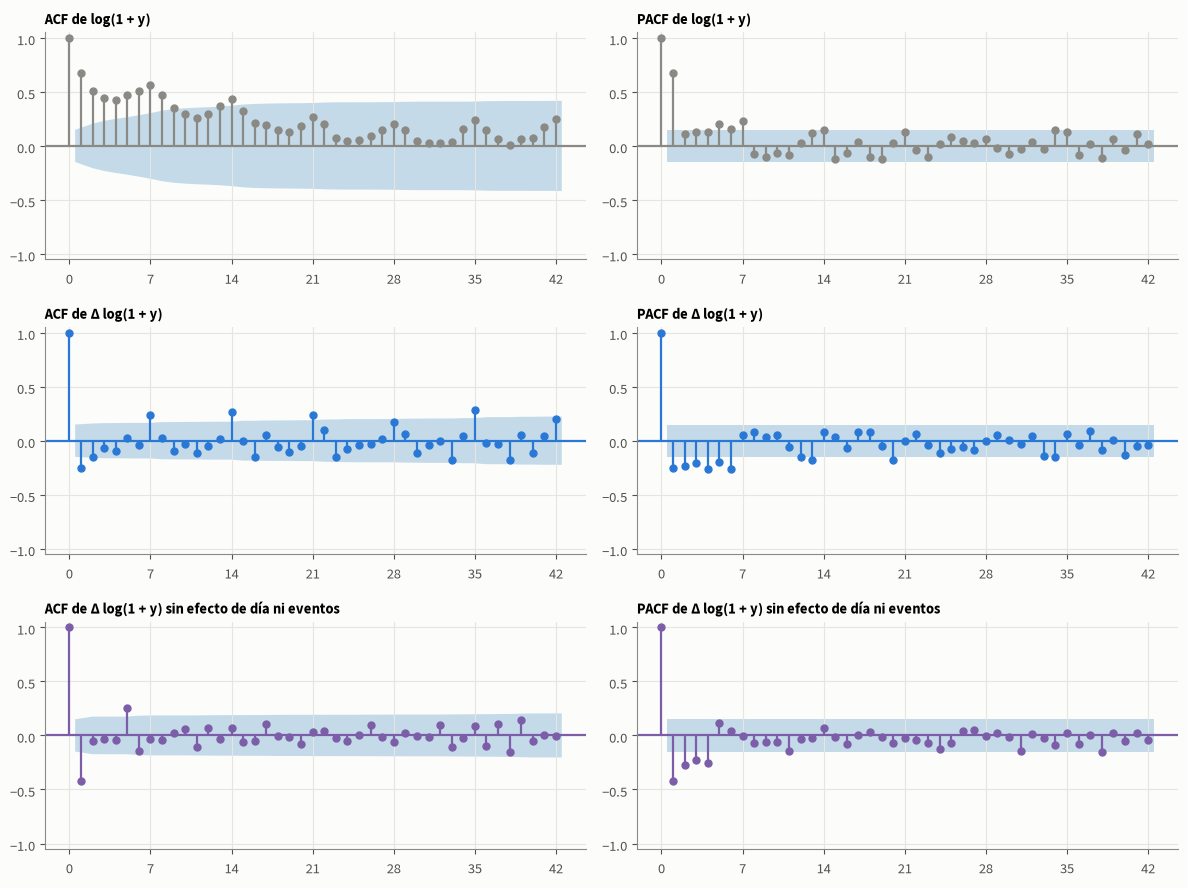


■ Autocorrelación en rezagos clave
  Regresores descontados: festivo, carnaval, dia_1, dia_2, dia_3, dia_4, dia_5, dia_6.


,log(1 + y),Δ log(1 + y),Δ log(1 + y) sin efecto de día ni eventos
rezago 1,0.67,-0.26,-0.42
rezago 2,0.51,-0.15,-0.05
rezago 7,0.57,0.24,-0.03
rezago 14,0.43,0.26,0.07
rezago 21,0.27,0.24,0.03


In [9]:
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.stattools import acf
from src.modelos import exogenas
# Mismos regresores que SARIMAX en 02; solo los que varían en la ventana (Black Friday aún no ocurre).
x=exogenas(calendario).loc[log_diag.index]; x=x.loc[:,x.nunique()>1]
dz=log_diag.diff().dropna(); dx=x.diff().loc[dz.index]
beta,*_=np.linalg.lstsq(dx.to_numpy(),dz.to_numpy(),rcond=None)
du=dz-dx.to_numpy()@beta
paneles=[('log(1 + y)',log_diag,TENUE),('Δ log(1 + y)',dz,COLOR['seleccion']),
         ('Δ log(1 + y) sin efecto de día ni eventos',du,COLOR['diagnostico'])]
fig,ejes=plt.subplots(3,2,figsize=(12,9))
for fila,(nombre,s,color) in zip(ejes,paneles):
    plot_acf(s,lags=42,ax=fila[0],color=color,vlines_kwargs={'colors':color})
    plot_pacf(s,lags=42,ax=fila[1],method='ywm',color=color,vlines_kwargs={'colors':color})
    fila[0].set_title(f'ACF de {nombre}',fontsize=10.5); fila[1].set_title(f'PACF de {nombre}',fontsize=10.5)
for eje in ejes.flat:
    eje.set_xticks(range(0,43,7)); eje.set_ylim(-1.05,1.05)
figura('acf_pacf_inicial')
rezagos=[1,2,7,14,21]
mostrar(pd.DataFrame({nombre:acf(s,nlags=21)[rezagos] for nombre,s,_ in paneles},
                     index=[f'rezago {k}' for k in rezagos]).round(2),
        'Autocorrelación en rezagos clave','Regresores descontados: '+', '.join(x.columns)+'.')

**Lectura del gráfico**

- **Nivel:** la ACF decae muy lento, con jorobas en 7, 14, 21…: persistencia por la tendencia más el ciclo semanal. Es la firma de una serie no estacionaria y coincide con §2.5.
- **Primera diferencia:** quedan picos positivos en los múltiplos de 7 que se apagan muy despacio y valores negativos entre ellos. La diferencia quitó la tendencia, pero no el patrón semanal.
- **Sin efecto de día ni eventos:** los picos semanales prácticamente desaparecen. Queda un pico negativo claro en el rezago 1 de la ACF y una PACF negativa que se apaga en los primeros rezagos: la firma de un componente **MA(1)** sobre la serie diferenciada, es decir, errores ARIMA(0,1,1) o ARIMA(1,1,1).

Mirar solo la serie con doble diferencia (Δ Δ7) llevaría a proponer un modelo "aerolínea" SARIMA(0,1,1)(0,1,1)₇. El tercer panel muestra directamente que, una vez descontados los indicadores de día, no queda estructura semanal que pida una diferencia estacional; §2.7 lo confirma con el AIC.

**Qué implica para el modelado.** Errores ARIMA de orden bajo con `d = 1` y la semana en regresores. En LightGBM, los picos en múltiplos de 7 justifican usar el mismo día de semanas anteriores como información (`lag_6`, `lag_13`, `lag_27`, `ultimo_mismo_dia`, `media_4_mismo_dia`).

### 2.7 AIC orientativo para los errores ARIMA

Se ajustan dos familias de SARIMAX sobre `log1p(y)` con los datos de la ventana de especificación, combinando `p, q ∈ {0, 1, 2}` con `d = 1`:

- **D (determinística):** sin diferencia estacional; la semana entra con los seis indicadores de día. Es la familia de 02.
- **E (estocástica):** diferencia estacional `D = 1` con un MA estacional y sin indicadores de día.

El **AIC** equilibra ajuste y número de parámetros: menor es mejor. Solo se comparan órdenes dentro de una familia, porque con distinta diferenciación la verosimilitud se calcula sobre datos distintos y los AIC dejan de ser comparables. Entre familias decidiría la validación. En esta ventana los únicos eventos de calendario con variación son `festivo` y `carnaval`; Black Friday y fin de año aún no han ocurrido.

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
familias={'D: semana determinística':((0,0,0,0),list(x.columns)),
          'E: semana estocástica':((0,1,1,7),[c for c in x.columns if not c.startswith('dia_')])}
filas=[]
for familia,(estacional,regresores) in familias.items():
    for p in range(3):
        for q in range(3):
            # Se registran los avisos de ajuste en vez de ocultarlos.
            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter('always')
                ajuste=SARIMAX(log_diag,exog=x[regresores],order=(p,1,q),seasonal_order=estacional,
                               trend='n').fit(disp=False,maxiter=300)
            filas.append(dict(familia=familia,orden=f'({p},1,{q})',AIC=ajuste.aic,BIC=ajuste.bic,
                              MA_estacional=ajuste.params.get('ma.S.L7',np.nan),
                              converge=bool(ajuste.mle_retvals.get('converged',False)),avisos=len(avisos)))
aic=pd.DataFrame(filas).sort_values(['familia','AIC']).reset_index(drop=True)
aic['delta_AIC']=aic.AIC-aic.groupby('familia').AIC.transform('min')
exportar(aic,'aic_diagnostico')
mostrar(aic.groupby('familia').head(4).round(3),'AIC orientativo con datos hasta el primer origen de selección (4 mejores por familia)',
        'delta_AIC se mide dentro de cada familia; entre familias no se compara.')
ref=aic[aic.familia.str.startswith('D')&aic.orden.eq('(1,1,1)')].iloc[0]
print(f'ARIMA(1,1,1) con indicadores (02): delta_AIC = {ref.delta_AIC:.2f}. '
      f'MA estacional en la familia E: {aic[aic.familia.str.startswith("E")].MA_estacional.min():.2f} a '
      f'{aic[aic.familia.str.startswith("E")].MA_estacional.max():.2f}. Convergen {aic.converge.sum()} de {len(aic)} ajustes.')


■ AIC orientativo con datos hasta el primer origen de selección (4 mejores por familia)
  delta_AIC se mide dentro de cada familia; entre familias no se compara.


,familia,orden,AIC,BIC,MA_estacional,converge,avisos,delta_AIC
0,D: semana determinística,"(0,1,1)",-59.565,-28.090,NaN,True,0,0.000
1,D: semana determinística,"(0,1,2)",-57.944,-23.322,NaN,True,0,1.621
2,D: semana determinística,"(1,1,1)",-57.904,-23.282,NaN,True,0,1.661
3,D: semana determinística,"(1,1,2)",-56.717,-18.947,NaN,True,0,2.848
9,E: semana estocástica,"(0,1,1)",-37.558,-22.029,-0.942,True,0,0.000
10,E: semana estocástica,"(0,1,2)",-36.060,-17.424,-0.933,True,0,1.498
11,E: semana estocástica,"(1,1,1)",-36.000,-17.365,-0.934,True,0,1.558
12,E: semana estocástica,"(2,1,2)",-34.983,-10.136,-0.920,True,1,2.575


ARIMA(1,1,1) con indicadores (02): delta_AIC = 1.66. MA estacional en la familia E: -0.94 a -0.88. Convergen 18 de 18 ajustes.


**Lectura de la tabla**

- En la familia D el menor AIC corresponde a ARIMA(0,1,1); ARIMA(1,1,1), la especificación fijada en 02, queda a 1,7 puntos. Una diferencia de AIC menor que 2 se considera respaldo prácticamente equivalente, y el término AR adicional da flexibilidad cuando la serie cambia de régimen (de crecimiento a meseta). Se mantiene (1,1,1).
- En la familia E el MA estacional estimado queda entre −0.88 y −0.94, cerca de −1. Un MA estacional de −1 cancela exactamente la diferencia estacional: es la señal de que Δ7 **sobra** y de que la semana es determinística. La señal aparece ya con datos anteriores a la primera emisión de selección.

**Qué implica para el modelado.** SARIMAX con errores ARIMA(1,1,1) sobre `log1p(y)`, seis indicadores de día y los indicadores de eventos de calendario, sin diferencia estacional. Es un candidato fijado antes de la selección, no la afirmación de que sea el único orden razonable: en 02 compite contra las referencias, ETS y LightGBM.

## 3. Eventos atípicos

Un evento atípico es un día o un tramo cuya demanda se aparta claramente de lo que harían esperar su nivel y su día de la semana. Hay tres maneras de tratarlo:

- **Modelar:** incluir un indicador que el modelo usa al ajustar y al pronosticar. Solo es posible si la fecha del evento se **conoce antes** de emitir el pronóstico.
- **Marcar:** identificarlo, describirlo y vigilar su efecto en los errores, sin darle al modelo información futura que no tendría.
- **Excluir:** sacarlo del análisis. Solo se justifica si los datos no representan demanda real.

La regla se fija **antes** de mirar magnitudes: previsible y recurrente → modelar; imprevisible → marcar; artefacto de datos → excluir. Los datos de esta sección (todo el historial previo a prueba) sirven para identificar los eventos y medir su tamaño, no para cambiar esa regla.

Las etiquetas vienen de dos fuentes, unidas en `sql/etiquetas_eventos.sql`: los indicadores de `sql/calendario.sql` (festivo nacional, Carnaval, Black Friday, cuatro días posteriores y fin de año) y la lista `EPISODIOS` de `src/configuracion.py` (semana previa a Navidad, huelga de camioneros y los partidos de Brasil en el Mundial anteriores a la prueba). Los episodios no son regresores: sirven para describir y para medir errores en 02.

### 3.1 Identificación: residuo STL robusto

Una lista de eventos solo encuentra lo que ya se sospechaba. Para buscar días raros sin prejuicio se descompone con STL robusta todo el historial previo a prueba y se estandariza su residuo con la mediana y la **MAD** (desviación absoluta mediana): `z = (residuo − mediana) / (1.4826 · MAD)`. A diferencia de la desviación estándar, la MAD casi no se altera por los propios extremos. Se marca un día si `|z| > 5`; el umbral habitual de 3.5 marca demasiados días de 2017, cuando los conteos bajos hacen más ruidoso el logaritmo.

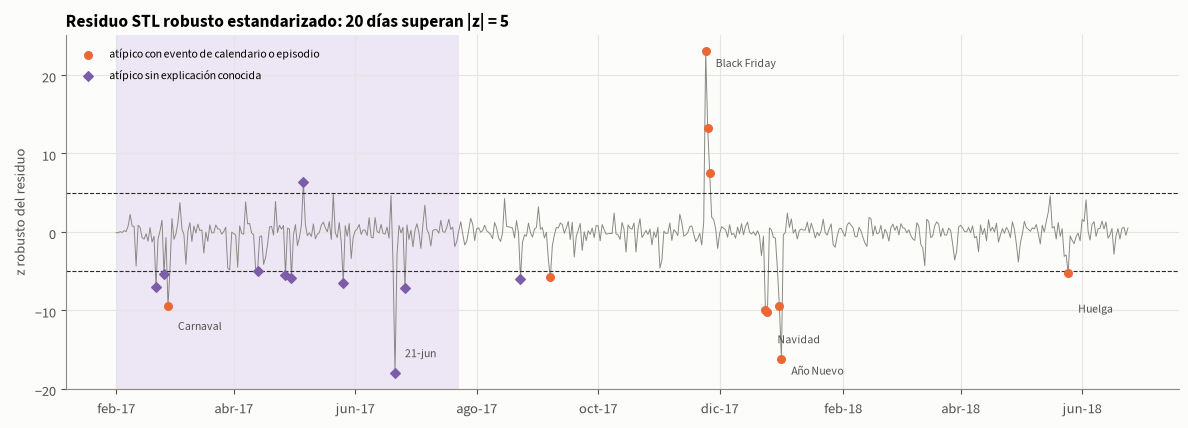


■ Días con |z robusto| > 5 en el historial previo a prueba
  Con el umbral habitual de 3.5 serían 44 días.


,fecha,dia_semana,y,z_robusto,eventos
0,2017-02-21,2,41,-7.10,— sin explicación —
1,2017-02-25,6,43,-5.32,— sin explicación —
2,2017-02-27,1,43,-9.52,carnaval
3,2017-04-13,4,60,-5.01,— sin explicación —
4,2017-04-27,4,80,-5.57,— sin explicación —
5,2017-04-30,7,68,-5.83,— sin explicación —
6,2017-05-06,6,109,6.36,— sin explicación —
7,2017-05-26,5,80,-6.49,— sin explicación —
8,2017-06-21,3,35,-17.99,— sin explicación —
9,2017-06-26,1,72,-7.21,— sin explicación —


In [11]:
UMBRAL_Z=5.0
residuos=pd.DataFrame({'fecha':y.index,'y':y.to_numpy(),'residuo':stl_pre.resid.to_numpy()})
con.register('residuos',residuos)
z_todos=consultar(con,'atipicos_stl.sql',[-1.0])
atipicos=consultar(con,'atipicos_stl.sql',[UMBRAL_Z]); exportar(atipicos,'atipicos_stl')
n_habitual=len(consultar(con,'atipicos_stl.sql',[3.5]))

fig,ax=plt.subplots(figsize=(12,4.4))
ax.axvspan(pd.Timestamp(INICIO),DIAGNOSTICO,color=FONDO['diagnostico'],lw=0)
ax.plot(z_todos.fecha,z_todos.z_robusto,color=TENUE,lw=.7)
for signo in (-1,1): ax.axhline(signo*UMBRAL_Z,color=TINTA,lw=.8,ls='--')
explicado=atipicos.eventos.notna()
ax.scatter(atipicos.fecha[explicado],atipicos.z_robusto[explicado],color=COLOR['prueba'],s=30,zorder=3,
           label='atípico con evento de calendario o episodio')
ax.scatter(atipicos.fecha[~explicado],atipicos.z_robusto[~explicado],color=COLOR['diagnostico'],marker='D',s=24,
           zorder=3,label='atípico sin explicación conocida')
z=z_todos.set_index('fecha').z_robusto
for nombre,fecha,dy in [('Carnaval','2017-02-27',-3),('21-jun','2017-06-21',2),('Black Friday','2017-11-24',-2),
                        ('Navidad','2017-12-25',-4),('Año Nuevo','2018-01-01',-2),('Huelga','2018-05-25',-5)]:
    f=pd.Timestamp(fecha)
    ax.annotate(nombre,(f,z[f]),xytext=(f+pd.Timedelta(days=5),z[f]+dy),fontsize=8.5,color='#52514e')
ax.set_ylabel('z robusto del residuo'); fechas_es(ax,'mes',2)
ax.legend(loc='upper left',fontsize=8.5)
ax.set_title(f'Residuo STL robusto estandarizado: {len(atipicos)} días superan |z| = {UMBRAL_Z:g}')
figura('atipicos_stl')
mostrar(atipicos.assign(eventos=atipicos.eventos.fillna('— sin explicación —'))[['fecha','dia_semana','y','z_robusto','eventos']].round({'z_robusto':2}),
        f'Días con |z robusto| > {UMBRAL_Z:g} en el historial previo a prueba',
        f'Con el umbral habitual de 3.5 serían {n_habitual} días.')

**Lectura del gráfico y de la tabla**

- Los atípicos más extremos tienen explicación de calendario: Black Friday (z ≈ 23) y sus dos días siguientes hacia arriba; Navidad, el 24 y el 31 de diciembre y Año Nuevo hacia abajo (z entre −9 y −16). También aparecen el Carnaval de 2017 y el festivo de Independencia (7-sep-2017).
- Diez días de febrero a agosto de 2017 superan el umbral sin explicación. En esa época se vendían 40–90 órdenes diarias y el ruido relativo es mayor; como la MAD se calcula con todo el historial, esos días resaltan más. El caso extremo es el **21-jun-2017** (35 órdenes, z ≈ −18): ningún calendario lo explica y lo más probable es una interrupción del registro o de la operación.
- La **huelga** apenas asoma en un día (25-may), aunque redujo la demanda a la mitad durante 11 días. La tendencia de STL se adapta a un cambio sostenido y lo absorbe: el residuo detecta picos aislados, no caídas prolongadas. Por eso la magnitud de la huelga se mide con el método de §3.2.

### 3.2 Magnitud: observado frente a esperado

Para cada día se calcula un **esperado**: la mediana del mismo día de la semana en las cuatro semanas previas (rezagos 7, 14, 21 y 28, solo pasado, en SQL). La mediana tolera que una de esas semanas también haya sido atípica. La razón observado/esperado resume el tamaño del evento: 2 significa el doble; 0.5, la mitad.


■ Magnitud de cada evento: observado frente al mismo día de las 4 semanas previas
  razón < 1: menos órdenes de lo esperado. Carnaval 2017 no entra: la serie empieza 26 días antes.


,evento,previsible,dias,desde,hasta,observado,esperado,razon_total,razon_min,razon_max
0,black_friday,True,1,2017-11-24,2017-11-24,1176.0,154.0,7.64,7.64,7.64
1,post_black_friday,True,4,2017-11-25,2017-11-28,1673.0,656.0,2.55,2.03,3.84
2,mundial_brasil,True,2,2018-06-17,2018-06-22,331.0,362.0,0.92,0.86,0.97
3,carnaval,True,2,2018-02-12,2018-02-13,442.0,554.0,0.80,0.75,0.85
4,festivo,True,12,2017-04-14,2018-05-01,1532.0,2035.0,0.75,0.30,1.47
5,pre_navidad,True,10,2017-12-14,2017-12-23,1575.0,2395.0,0.66,0.45,0.81
6,huelga_camioneros,False,11,2018-05-21,2018-05-31,1519.0,2998.0,0.51,0.41,0.66
7,fin_anio,True,9,2017-12-24,2018-01-01,1010.0,1997.0,0.51,0.28,0.68


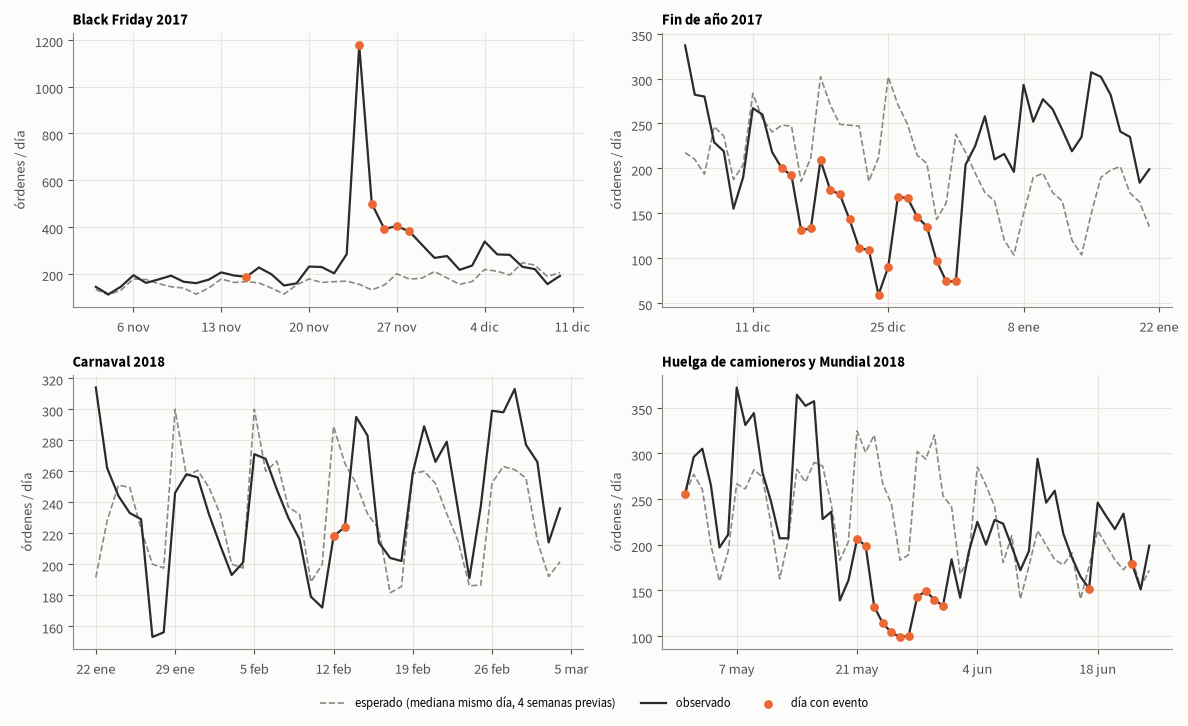

In [12]:
# Esperado = mediana del mismo día en las 4 semanas previas (solo pasado), calculado en SQL.
esperados=consultar(con,'esperado_mismo_dia.sql',[P]); con.register('esperados',esperados)
magnitud=consultar(con,'resumen_eventos.sql'); exportar(magnitud,'magnitud_eventos')
mostrar(magnitud.round({'razon_total':2,'razon_min':2,'razon_max':2}),'Magnitud de cada evento: observado frente al mismo día de las 4 semanas previas',
        'razón < 1: menos órdenes de lo esperado. Carnaval 2017 no entra: la serie empieza 26 días antes.')

e=esperados.assign(fecha=pd.to_datetime(esperados.fecha)).set_index('fecha')
VENTANAS_EVENTO=[('Black Friday 2017','2017-11-03','2017-12-10'),('Fin de año 2017','2017-12-04','2018-01-21'),
                 ('Carnaval 2018','2018-01-22','2018-03-04'),('Huelga de camioneros y Mundial 2018','2018-05-01',P)]
fig,ejes=plt.subplots(2,2,figsize=(12,7))
for eje,(titulo,desde,hasta) in zip(ejes.flat,VENTANAS_EVENTO):
    t=e.loc[desde:hasta]
    eje.plot(t.index,t.esperado,color=TENUE,lw=1.2,ls='--',label='esperado (mediana mismo día, 4 semanas previas)')
    eje.plot(t.index,t.y,color=TINTA,lw=1.6,label='observado')
    marcados=t[t.eventos.notna()]
    eje.scatter(marcados.index,marcados.y,color=COLOR['prueba'],s=28,zorder=3,label='día con evento')
    eje.set_title(titulo,fontsize=10.5); eje.set_ylabel('órdenes / día')
    fechas_es(eje,'semana',1 if len(t)<=42 else 2)
plt.tight_layout()
fig.legend(*ejes[0,0].get_legend_handles_labels(),loc='lower center',ncol=3,bbox_to_anchor=(.5,-.04),fontsize=9)
figura('eventos_atipicos')

**Lectura de la tabla y del gráfico**

- **Black Friday 2017:** 1,176 órdenes frente a unas 154 esperadas (×7.6). Es el día más alto de la serie.
- **Cuatro días posteriores:** ×2.5 en conjunto, bajando de ×3.8 a ×2.0. El efecto se arrastra y se apaga en unos cinco días.
- **Fin de año:** cerca de ×0.5 entre el 24-dic y el 1-ene, con los peores días alrededor de ×0.3. La caída dura toda la semana, no solo los festivos. Además, **empieza unos diez días antes** de que se active `fin_anio`: del 14 al 23 de diciembre la razón baja de 0.81 a 0.45, probablemente porque las compras dejan de llegar a tiempo para Navidad. En la tabla es la fila `pre_navidad`: ×0.66 en conjunto, durante diez días.
- **Festivos nacionales:** ×0.75 en conjunto, pero muy heterogéneos (de ×0.30 a ×1.47). Un único coeficiente será un promedio aproximado.
- **Carnaval 2018:** cerca de ×0.80 el lunes y el martes. Carnaval 2017 no aparece en la tabla porque la serie empieza 26 días antes, pero su residuo STL estuvo entre los más negativos (§3.1).
- **Huelga de camioneros (21–31 may 2018):** cerca de ×0.51 sostenido durante 11 días y una recuperación gradual durante la primera semana de junio (razones de 0.75 a 0.85 hasta el 5-jun). Después de la huelga el esperado queda subestimado, porque dos de las cuatro semanas de referencia contienen días de huelga.
- **Partidos de Brasil (17 y 22 de junio):** cerca de ×0.92. Es un efecto pequeño y medido con solo dos días.

### 3.3 Decisión por evento: modelar, marcar o excluir

| Evento | ¿Previsible? | Magnitud | Tratamiento | Justificación y efecto en 02 |
|---|---|---|---|---|
| Black Friday (24-nov-2017) | Sí: viernes posterior al cuarto jueves de noviembre | ×7.6 | **Modelar** (`black_friday`) | Recurrente y con fecha conocida; excluirlo dejaría sin preparar el siguiente. Limitación: en selección, el primer Black Friday se pronostica sin haber visto otro y su coeficiente no se puede estimar antes. Esos errores serán grandes y se reportan. |
| Cuatro días posteriores | Sí | ×2.5 | **Modelar** (`post_black_friday`) | Efecto de arrastre con fecha conocida. |
| Fin de año (24-dic a 1-ene) | Sí | ×0.5 | **Modelar** (`fin_anio`) | La caída dura toda la semana; un indicador de festivo de un día no la captura. |
| Semana previa a Navidad (≈ 14 a 23-dic) | Sí (fecha fija) | ×0.45 a ×0.81 | **Marcar** | `fin_anio` empieza el 24-dic y no la cubre. Pero esta evidencia solo existe en diciembre de 2017, que es objetivo de selección: ampliar el indicador con ella sería especificar con datos de evaluación. Se documenta como limitación (02 subestimará la caída previa a Navidad) hasta tener un segundo diciembre que la confirme; el episodio `pre_navidad` permite medir ese error en 02. |
| Festivos nacionales | Sí (librería `holidays`) | ×0.75 (0.30–1.47) | **Modelar** (`festivo`) | Fechas conocidas; el coeficiente promedia efectos heterogéneos. |
| Carnaval (lunes y martes) | Sí: 48 y 47 días antes de la Pascua | ×0.80 en 2018; residuo muy negativo en 2017 | **Modelar** (`carnaval`) | No es festivo nacional, así que no entraba en `festivo`; `holidays` lo incluye en su categoría opcional. La evidencia de 2017 está dentro de la ventana de especificación, de modo que incorporarlo no usa datos que se van a evaluar. |
| Huelga de camioneros (21–31 may 2018) | No | ×0.51 durante 11 días | **Marcar** | No se podía anticipar con cuatro semanas de antelación: darle al modelo un indicador futuro sería fuga de información. Se conserva en las métricas, porque la operación real enfrenta choques así; excluirla haría las métricas y los intervalos de calibración más optimistas. 02 reporta aparte el error en esa ventana. Una alternativa sería usar un indicador solo en el ajuste y quitar esos días de las métricas: ayuda a estimar parámetros, pero hace la evaluación más benigna de lo que sería en operación, así que no se adopta. |
| Partidos de Brasil, Mundial 2018 | Fase de grupos, sí | ×0.92 en 2 días | **Solo diagnóstico** | Dos días no permiten estimar un efecto y los demás partidos caen en prueba. |
| 21-jun-2017 y otros días sin explicación | No | 35 órdenes frente a ~110 | **Marcar y conservar** | Sin una causa externa conocida no hay base para imputarlos. El logaritmo y la STL robusta limitan su influencia descriptiva; en SARIMAX actúan como una innovación grande. |
| Arranque (2016 y ene-2017) y truncamiento (desde 20-ago-2018) | — | Artefactos de los datos | **Excluir** | No representan demanda. El Módulo 0 fijó `INICIO` y `CORTE` por cobertura. |

### 3.4 Cómo se codifican las fechas especiales

Al ejecutar `preparar(con)` al inicio del notebook, [la función de datos](../src/datos.py) obtiene los festivos nacionales de Brasil con `holidays`. Después, `sql/calendario.sql` crea una fila por fecha y cinco columnas binarias: `festivo`, `carnaval`, `black_friday`, `post_black_friday` y `fin_anio`. **1 significa que se cumple la regla de calendario; 0, que no se cumple.**

`carnaval` marca el lunes y el martes de Carnaval, tomados de la categoría opcional de `holidays` (dependen de la Pascua). Black Friday es el viernes siguiente al cuarto jueves de noviembre. `post_black_friday` marca sus cuatro días posteriores. `fin_anio` marca del 24 al 31 de diciembre y el 1 de enero. Una fecha puede tener más de un indicador: Navidad es festivo y también pertenece al período de fin de año.

La tabla siguiente muestra el resultado real del cálculo, incluidos el lunes de Carnaval de 2018, un día de huelga y un festivo futuro. `pedidos_observados` se añade **solo para entender el ejemplo**; no se usa para crear los indicadores. En septiembre de 2018 esa columna está vacía (la fecha es posterior al corte) mientras que el festivo ya se conoce: **el calendario futuro es información disponible; el número de compras futuras no lo es.** Esa distinción permite usar el día de la semana o un festivo de la fecha objetivo sin cometer fuga de información.

In [13]:
# Fechas concretas calculadas por SQL y sus compras, cuando existen.
calendario_ejemplos=consultar(con,'ejemplos_calendario.sql'); exportar(calendario_ejemplos,'ejemplos_calendario')
mostrar(calendario_ejemplos,'Ejemplos de cómo el calendario codifica fechas especiales',
        'pedidos_observados es solo ilustrativo; no participa en los indicadores.')
# Cuántos días activa cada indicador; pueden coincidir en una fecha.
resumen_calendario=consultar(con,'resumen_calendario.sql'); exportar(resumen_calendario,'resumen_calendario')
mostrar(resumen_calendario,'Días marcados por cada indicador de calendario, por año',
        'Incluye las fechas futuras del horizonte de pronóstico.')
print('Black Friday 2017 marca 1; el día siguiente marca post_black_friday=1.')
print('El 21/05/2018 no recibe un indicador de huelga futura.')


■ Ejemplos de cómo el calendario codifica fechas especiales
  pedidos_observados es solo ilustrativo; no participa en los indicadores.


,fecha,dia_semana,festivo,carnaval,black_friday,post_black_friday,fin_anio,pedidos_observados
0,2017-11-24,5,0,0,1,0,0,1176
1,2017-11-25,6,0,0,0,1,0,499
2,2017-12-24,7,0,0,0,0,1,59
3,2017-12-25,1,1,0,0,0,1,90
4,2018-01-01,1,1,0,0,0,1,74
5,2018-02-12,1,0,1,0,0,0,218
6,2018-05-21,1,0,0,0,0,0,206
7,2018-09-07,5,1,0,0,0,0,<NA>



■ Días marcados por cada indicador de calendario, por año
  Incluye las fechas futuras del horizonte de pronóstico.


,anio,dias_calendario,dias_festivos_nacionales,dias_carnaval,dias_black_friday,dias_post_black_friday,dias_fin_anio
0,2017,334,8.0,2.0,1.0,4.0,8.0
1,2018,259,5.0,2.0,0.0,0.0,1.0


Black Friday 2017 marca 1; el día siguiente marca post_black_friday=1.
El 21/05/2018 no recibe un indicador de huelga futura.


## 4. Decisiones que este análisis fija para 02

| Evidencia (sección) | Decisión | Dónde se aplica en 02 |
|---|---|---|
| Crecimiento en 2017 y meseta en 2018 (§2.1) | No extrapolar una tendencia fija | SARIMAX sin deriva (`trend='n'`), ETS con tendencia amortiguada, variantes LightGBM con objetivo relativo al nivel reciente |
| Amplitud proporcional al nivel (§2.2, §2.3, §2.4) | Modelar `log1p(y)` y volver con `expm1` | SARIMAX; objetivo relativo `log(1+y) − log(1+media_28)` de LightGBM |
| Nivel no estacionario; primera diferencia estacionaria (§2.5) | `d = 1` | Errores ARIMA(1,1,1) |
| Patrón semanal estable; MA estacional ≈ −1; sin picos semanales tras descontar los indicadores (§2.2, §2.6, §2.7) | Semana determinística, sin `D = 1` | Indicadores `dia_1…dia_6` en `exogenas()`; `dia_semana` en LightGBM |
| Pico negativo en el rezago 1 tras descontar la semana; ΔAIC < 2 frente al mejor orden (§2.6, §2.7) | Errores ARIMA(1,1,1), fijados antes de la selección | `SARIMAX_calendario` |
| Picos en múltiplos de 7 en la ACF (§2.6) | Usar el mismo día de semanas anteriores | `lag_6`, `lag_13`, `lag_27`, `ultimo_mismo_dia`, `media_4_mismo_dia` en `sql/features.sql` |
| Black Friday, días posteriores, fin de año, festivos y Carnaval (§3) | **Modelar** con indicadores de calendario conocidos de antemano | `festivo`, `carnaval`, `black_friday`, `post_black_friday`, `fin_anio` |
| Huelga imprevisible (§3) | **Marcar**: sin indicador futuro, dentro de las métricas, error reportado aparte | Errores por evento (02 §15) |
| Caída previa a Navidad vista solo en selección (§3) | Limitación documentada, **sin cambio** | Episodio `pre_navidad`: su error se mide en 02 §15 |
| Ventana de especificación corta (173 días) | Toda conclusión se controla con el historial previo a prueba, nunca con la prueba | — |

In [14]:
# Cerramos el acceso de solo lectura; el siguiente notebook es autónomo.
con.close()
print('Continúa con B_series_02_modelado.ipynb.')

Continúa con B_series_02_modelado.ipynb.
